# IRDS Elbow Flexion — FSM Rep Count Benchmark

Validates the `ElbowFSM` on IntelliRehabDS elbow flexion recordings.
Uses **Kinect 3D joint positions** to compute the elbow angle, then feeds it
into the same FSM used in the live physiotherapy app.

**Before running:** upload the IRDS skeleton CSV files to Google Drive and
set `IRDS_DIR` in Step 1 to point at that folder.

In [18]:
# ============================================================
# STEP 1 — Settings
# ============================================================
import os, glob, shutil, subprocess, sys
import numpy as np
import pandas as pd

# ----------------------------------------------------------------
# >>> UPDATE THESE TWO PATHS <<<
# IRDS_DIR  : the folder in your Drive where you put the IRDS CSVs
#             e.g. '/content/drive/MyDrive/irds'
#             or   '/content/drive/MyDrive/rehab_data/irds'
# REPO_DIR  : leave as-is unless your repo clone is elsewhere
# ----------------------------------------------------------------
IRDS_DIR = '/content/drive/MyDrive/SkeletonData/SkeletonData'   # <-- CHANGE THIS
REPO_DIR = '/content/repo'
REPO_URL = 'https://github.com/suvini2001/AI-based-Physiotherapy-project-.git'
BRANCH   = 'main'

# IRDS gesture labels for elbow flexion
# GestureLabel 0 = elbow flexion left, 1 = elbow flexion right
ELBOW_LABELS = {'0', '1'}

# Kinect joint indices used for the elbow angle (shoulder - elbow - wrist)
# Kinect v2 body joints: 5=ShoulderRight, 9=ElbowRight, 10=WristRight
#                        4=ShoulderLeft,  6=ElbowLeft,  7=WristLeft
JOINTS_RIGHT = (22, 6, 3)
JOINTS_LEFT  = (23, 7, 22)

VIDEO_FPS = 30.0  # Kinect records at ~30 fps

print('Settings ready.')
print(f'IRDS_DIR : {IRDS_DIR}')
print(f'REPO_DIR : {REPO_DIR}')

Settings ready.
IRDS_DIR : /content/drive/MyDrive/SkeletonData/SkeletonData
REPO_DIR : /content/repo


In [5]:
import glob
print(glob.glob('/content/drive/MyDrive/**/*', recursive=False))

['/content/drive/MyDrive/Colab Notebooks/Google Colaboratory - Basic.ipynb', '/content/drive/MyDrive/Colab Notebooks/2.2 Python Basics.ipynb', '/content/drive/MyDrive/Colab Notebooks/Basic Data Types in Python.ipynb', '/content/drive/MyDrive/Colab Notebooks/List Tuple Set Dictionary.ipynb', '/content/drive/MyDrive/Colab Notebooks/4.1 Where to Collect Data for machine learning.ipynb', '/content/drive/MyDrive/Colab Notebooks/4.2 Importing Datasets  through Kaggle API.ipynb', '/content/drive/MyDrive/Colab Notebooks/4.3 Handeling Missing Values.ipynb', '/content/drive/MyDrive/Colab Notebooks/4.4 Data Stadarization.ipynb', '/content/drive/MyDrive/Colab Notebooks/Untitled (4)', '/content/drive/MyDrive/Colab Notebooks/4.5 Label Encoding.ipynb', '/content/drive/MyDrive/Colab Notebooks/4.6 Train Test Split.ipynb', '/content/drive/MyDrive/Colab Notebooks/4.7 Handeling imbalanced Dataset.ipynb', '/content/drive/MyDrive/Colab Notebooks/Cyber Security - VOLUME 3.zip', '/content/drive/MyDrive/Colab 

In [16]:
# ============================================================
# STEP 2 — Mount Drive and check IRDS files are there
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

files = glob.glob(os.path.join(IRDS_DIR, '**/*.csv'), recursive=True) + \
        glob.glob(os.path.join(IRDS_DIR, '**/*.txt'), recursive=True)

if not files:
    raise FileNotFoundError(
        f'No CSV/TXT files found in {IRDS_DIR}\n'
        f'Check that IRDS_DIR in Step 1 matches where you uploaded the files.'
    )

print(f'Found {len(files)} files in IRDS_DIR')
print('First 5:', [os.path.basename(f) for f in files[:5]])

elbow_files = []
for f in files:
    name = os.path.basename(f).replace('.txt','').replace('.csv','')
    parts = name.split('_')
    if len(parts) < 5:
        continue
    # skip reference/posture frames
    suffix = '_'.join(parts[5:]) if len(parts) > 5 else ''
    if 'Stand-frame' in suffix:
        continue
    if parts[2] in ELBOW_LABELS:
        elbow_files.append({
            'path': f,
            'subject':  parts[0],
            'date':     parts[1],
            'gesture':  parts[2],
            'rep_num':  parts[3],
            'correct':  parts[4],
            'position': suffix,   # stand / chair / wheelchair / sit
            'side':     'left' if parts[2] == '0' else 'right',
        })

print(f'Elbow flexion files (after excluding Stand-frame): {len(elbow_files)}')
print(pd.DataFrame(elbow_files)['position'].value_counts())

Mounted at /content/drive
Found 5178 files in IRDS_DIR
First 5: ['204_18_3_30_2_chair.txt', '202_18_8_41_1_stand.txt', '210_18_4_4_1_wheelchair.txt', '306_18_6_13_1_stand.txt', '303_18_5_9_1_stand.txt']
Elbow flexion files (after excluding Stand-frame): 1048
position
stand         540
chair         306
wheelchair    154
sit            48
Name: count, dtype: int64


In [17]:
sample = elbow_files[0]
print(f"Sample file: {os.path.basename(sample['path'])}")
print(f"Side: {sample['side']}, Subject: {sample['subject']}")
df = pd.read_csv(sample['path'], header=None).values.astype(float)
print(f"Shape: {df.shape}")

candidates = []
for js in range(25):
    for je in range(25):
        for jw in range(25):
            if js==je or je==jw or js==jw: continue
            try:
                a = angle3(df, js, je, jw)
                r = np.nanmax(a) - np.nanmin(a)
                if r > 40:
                    candidates.append((r, js, je, jw, np.nanmin(a), np.nanmax(a)))
            except: pass

candidates.sort(reverse=True)
print(f"\n{'js':>5} {'je':>5} {'jw':>5}  {'min':>7} {'max':>7} {'range':>7}")
for r, js, je, jw, mn, mx in candidates[:10]:
    print(f"  {js:3d}  {je:3d}  {jw:3d}   {mn:7.1f} {mx:7.1f} {r:7.1f}")

Sample file: 201_18_1_6_2_wheelchair.txt
Side: right, Subject: 201
Shape: (93, 75)

   js    je    jw      min     max   range
   22    6    3       9.7   175.2   165.5
    3    6   22       9.7   175.2   165.5
   20    7    6      12.0   175.5   163.5
    6    7   20      12.0   175.5   163.5
   20    6    7       4.3   167.7   163.4
    7    6   20       4.3   167.7   163.4
    7   22    3       9.2   172.3   163.1
    3   22    7       9.2   172.3   163.1
   22    7    3       6.5   169.4   162.9
    3    7   22       6.5   169.4   162.9


In [7]:
# ============================================================
# STEP 3 — Clone repo and fetch ElbowFSM from main branch
# ============================================================
os.chdir('/content')
if os.path.exists(REPO_DIR):
    shutil.rmtree(REPO_DIR)
subprocess.run(['git', 'clone', '-q', '-b', BRANCH, REPO_URL, REPO_DIR], check=True)
sys.path.insert(0, REPO_DIR)

from exercise_state import ElbowFSM
from calibration import fit_curve, apply_calibration
print('ElbowFSM imported OK')

ElbowFSM imported OK


In [8]:
# ============================================================
# STEP 4 — Inspect one file to confirm column layout
# ============================================================
sample = pd.read_csv(elbow_files[0]['path'], header=None)
print('Shape:', sample.shape)
print('First 3 rows:')
print(sample.head(3))
print()
print('Each row = one frame.')
print('Kinect v2 has 25 joints x 3 coords (X,Y,Z) = 75 columns expected.')
print('If shape[1] != 75, update JOINTS_RIGHT / JOINTS_LEFT in Step 1.')

Shape: (146, 75)
First 3 rows:
         0         1         2         3         4         5         6   \
0  0.041989  0.042422  1.971252  0.037979  0.344612  1.895001  0.035696   
1  0.041952  0.041249  1.971223  0.037803  0.344709  1.896927  0.034748   
2  0.041668  0.040161  1.971386  0.037802  0.344868  1.898923  0.034913   

         7         8         9   ...        65        66        67        68  \
0  0.638124  1.813046  0.011371  ...  1.587328 -0.093663 -0.034842  1.691300   
1  0.639276  1.816641  0.009602  ...  1.576123 -0.094124 -0.034263  1.689798   
2  0.640437  1.819827  0.008029  ...  1.579115 -0.094414 -0.034355  1.690560   

         69        70        71        72        73        74  
0  0.287779 -0.035998  1.622510  0.249444 -0.028157  1.611740  
1  0.320805 -0.091000  1.610439  0.258433 -0.028882  1.622250  
2  0.322918 -0.088642  1.611237  0.260139 -0.026688  1.623834  

[3 rows x 75 columns]

Each row = one frame.
Kinect v2 has 25 joints x 3 coords (X,Y,Z) = 

In [19]:
# ============================================================
# STEP 5 — Helper: compute elbow angle from 3D joint positions
# ============================================================
def angle_from_joints(data, j_shoulder, j_elbow, j_wrist):
    """Compute elbow angle (degrees) for every frame.
    data : (N, 75) array — 25 joints * 3 columns each (X Y Z).
    Joint k occupies columns [3k, 3k+1, 3k+2].
    """
    S = data[:, j_shoulder*3 : j_shoulder*3+3]
    E = data[:, j_elbow*3   : j_elbow*3+3]
    W = data[:, j_wrist*3   : j_wrist*3+3]

    v1 = S - E
    v2 = W - E
    norm1 = np.linalg.norm(v1, axis=1, keepdims=True)
    norm2 = np.linalg.norm(v2, axis=1, keepdims=True)
    # avoid divide-by-zero on missing frames
    safe = (norm1 > 1e-6) & (norm2 > 1e-6)
    cos_a = np.where(
        safe.squeeze(),
        np.clip((v1 * v2).sum(axis=1) / (norm1 * norm2).squeeze(), -1, 1),
        np.nan
    )
    return np.degrees(np.arccos(cos_a))


def run_fsm(signal, fps=30.0):
    """Run ElbowFSM on an angle series. Returns (reps_counted, incomplete)."""
    sig = np.asarray(signal, float)
    fsm = ElbowFSM()
    cal_ok = fsm.calibrate_from_signal(sig, fps=fps)
    for i, a in enumerate(sig):
        if np.isfinite(a):
            fsm.update(a, i / fps)
    fsm.flush(len(sig) / fps)
    return fsm.rep_count, len(fsm.incomplete_attempts), cal_ok


print('Helpers defined.')

Helpers defined.


In [28]:
#step 6
rows = []
skipped = 0

for info in elbow_files:
    data = load_file(info['path'])
    if data is None:
        skipped += 1
        continue

    j_s, j_e, j_w = (JOINTS_RIGHT if info['side'] == 'right' else JOINTS_LEFT)
    signal = angle3(data, j_s, j_e, j_w)

    # each file is exactly 1 repetition
    gt = 1
    counted, incomplete, cal_ok = run_fsm(signal, VIDEO_FPS)

    rows.append(dict(
        subject=info['subject'],
        side=info['side'],
        correct=info['correct'],
        position=info['position'],
        gt=gt,
        counted=counted,
        incomplete=incomplete,
        detected=counted + incomplete,
        calibrated=cal_ok,
        n_frames=len(signal),
        angle_min=np.nanmin(signal),
        angle_max=np.nanmax(signal),
        angle_range=np.nanmax(signal) - np.nanmin(signal),
    ))

print(f'Skipped {skipped} unreadable files')
df_rep = pd.DataFrame(rows)
df_rep['err']     = (df_rep['counted']  - df_rep['gt']).abs()
df_rep['err_det'] = (df_rep['detected'] - df_rep['gt']).abs()

print(f'Processed {len(df_rep)} individual reps')
print(f'Calibration OK: {df_rep["calibrated"].sum()}/{len(df_rep)}')
print(f'Zero count: {(df_rep["counted"]==0).sum()}/{len(df_rep)}')
print(f'Counted exactly 1: {(df_rep["counted"]==1).sum()}/{len(df_rep)}')
print()

# Results
def summary(d, label=''):
    n = len(d)
    if n == 0: return
    mae  = d['err'].mean()
    obo  = 100*(d['err']<=1).mean()
    exact= 100*(d['err']==0).mean()
    obo_det = 100*(d['err_det']<=1).mean()
    zero = 100*(d['counted']==0).mean()
    print(f'{label:35s} n={n:4d}  MAE={mae:.2f}  OBO={obo:.1f}%  '
          f'Exact={exact:.1f}%  OBO_det={obo_det:.1f}%  Zero={zero:.1f}%')

print('='*95)
print('IRDS — FSM on individual rep files (GT=1 per file)')
print('='*95)
summary(df_rep,                              'ALL')
summary(df_rep[df_rep.correct=='1'],         'Correct reps')
summary(df_rep[df_rep.correct=='2'],         'Incorrect reps')
summary(df_rep[df_rep.side=='right'],        'Right arm')
summary(df_rep[df_rep.side=='left'],         'Left arm')
summary(df_rep[df_rep.position=='stand'],    'Standing')
summary(df_rep[df_rep.position=='chair'],    'Chair')
summary(df_rep[df_rep.position=='wheelchair'],'Wheelchair')

FSM calibrated: FLEX=61°  EXTEND=129°  range=151°
FSM calibrated: FLEX=120°  EXTEND=152°  range=70°
FSM calibrated: FLEX=122°  EXTEND=148°  range=57°
FSM calibrated: FLEX=34°  EXTEND=62°  range=62°
FSM calibrated: FLEX=35°  EXTEND=53°  range=40°
FSM calibrated: FLEX=91°  EXTEND=143°  range=115°
FSM calibrated: FLEX=87°  EXTEND=114°  range=60°
FSM calibrated: FLEX=49°  EXTEND=98°  range=108°
FSM calibrated: FLEX=89°  EXTEND=115°  range=58°
FSM calibrated: FLEX=73°  EXTEND=121°  range=106°
FSM calibrated: FLEX=104°  EXTEND=140°  range=78°
FSM calibrated: FLEX=66°  EXTEND=118°  range=116°
FSM calibrated: FLEX=91°  EXTEND=105°  range=30°
FSM calibrated: FLEX=35°  EXTEND=66°  range=67°
FSM calibrated: FLEX=58°  EXTEND=74°  range=35°
FSM calibrated: FLEX=99°  EXTEND=133°  range=75°
FSM calibrated: FLEX=51°  EXTEND=76°  range=56°
FSM calibrated: FLEX=113°  EXTEND=135°  range=49°
FSM calibrated: FLEX=87°  EXTEND=135°  range=106°
FSM calibrated: FLEX=96°  EXTEND=109°  range=30°
FSM calibrated: 

In [22]:
# ============================================================
# STEP 7 — Results
# ============================================================
def summary(d, label=''):
    n   = len(d)
    mae = d['err'].mean()
    obo = 100 * (d['err'] <= 1).mean()
    exact = 100 * (d['err'] == 0).mean()
    obo_det = 100 * (d['err_det'] <= 1).mean()
    zero = 100 * (d['counted'] == 0).mean()
    print(f'{label:30s}  n={n:3d}  MAE={mae:.2f}  OBO={obo:.1f}%  '
          f'Exact={exact:.1f}%  OBO_detected={obo_det:.1f}%  Zero={zero:.1f}%')

print('='*90)
print('IRDS Elbow Flexion — ElbowFSM rep count benchmark')
print('='*90)
summary(df_rep,                            'ALL')
summary(df_rep[df_rep.correct=='1'],       'Correct reps only')
summary(df_rep[df_rep.correct=='2'],       'Incorrect reps only')
summary(df_rep[df_rep.side=='right'],      'Right arm')
summary(df_rep[df_rep.side=='left'],       'Left arm')
print()
print('Per-subject breakdown:')
for subj, g in df_rep.groupby('subject'):
    summary(g, f'  Subject {subj}')

print()
print('Comparison with REHAB24-6 result:')
print('  REHAB24-6  D_2D_PerView  OBO=17.9%  (exercise mismatch — arm-VW/table push-up)')
print(f'  IRDS       ElbowFSM      OBO={100*(df_rep.err<=1).mean():.1f}%  (correct exercise — elbow flexion)')

IRDS Elbow Flexion — ElbowFSM rep count benchmark
ALL                             n= 66  MAE=15.83  OBO=0.0%  Exact=0.0%  OBO_detected=0.0%  Zero=95.5%
Correct reps only               n= 49  MAE=17.69  OBO=0.0%  Exact=0.0%  OBO_detected=0.0%  Zero=93.9%
Incorrect reps only             n= 17  MAE=10.47  OBO=0.0%  Exact=0.0%  OBO_detected=0.0%  Zero=100.0%
Right arm                       n= 35  MAE=15.57  OBO=0.0%  Exact=0.0%  OBO_detected=0.0%  Zero=97.1%
Left arm                        n= 31  MAE=16.13  OBO=0.0%  Exact=0.0%  OBO_detected=0.0%  Zero=93.5%

Per-subject breakdown:
  Subject 101                   n=  2  MAE=22.00  OBO=0.0%  Exact=0.0%  OBO_detected=0.0%  Zero=100.0%
  Subject 102                   n=  2  MAE=23.50  OBO=0.0%  Exact=0.0%  OBO_detected=0.0%  Zero=50.0%
  Subject 103                   n=  2  MAE=24.00  OBO=0.0%  Exact=0.0%  OBO_detected=0.0%  Zero=100.0%
  Subject 104                   n=  2  MAE=13.00  OBO=0.0%  Exact=0.0%  OBO_detected=0.0%  Zero=100.0%
  Su

File: /content/drive/MyDrive/SkeletonData/SkeletonData/Simplified/214_18_0_1_2_Stand-frame.txt
Shape: (146, 75)
Side: left, Subject: 214

First 3 rows (raw):
[[0.04198912 0.04242221 1.971252   0.03797885 0.3446116  1.895001
  0.03569569 0.6381238  1.813046   0.01137059 0.7566448  1.771822  ]
 [0.0419523  0.04124862 1.971223   0.03780252 0.3447087  1.896927
  0.03474789 0.6392756  1.816641   0.00960241 0.7590045  1.776206  ]
 [0.04166816 0.04016082 1.971386   0.03780239 0.3448682  1.898923
  0.034913   0.6404373  1.819827   0.00802946 0.7609136  1.779961  ]]

Kinect v2 standard: min=137.6  max=156.7  NaN=0
Alternative:        min=130.7  max=151.3  NaN=0
Columns in file: 75  (25 joints if 3-col, 19 if 4-col)


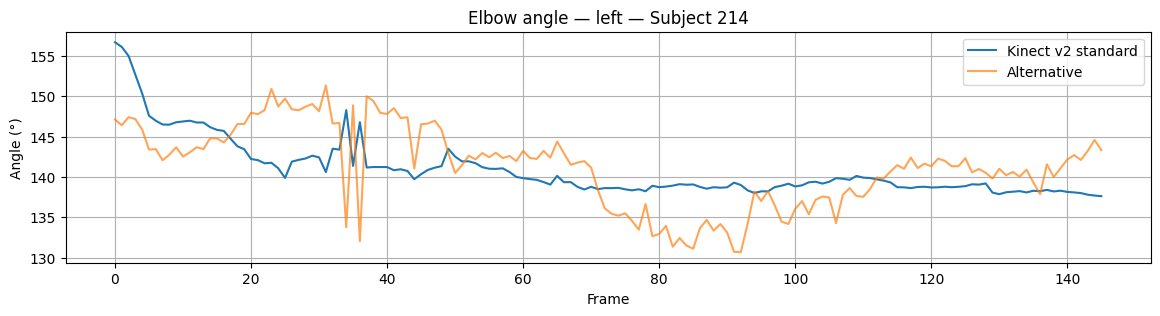

In [12]:
# Paste this as a new cell and run it
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load one file
sample = elbow_files[0]
df = pd.read_csv(sample['path'], header=None).values.astype(float)

print(f"File: {sample['path']}")
print(f"Shape: {df.shape}")
print(f"Side: {sample['side']}, Subject: {sample['subject']}")
print()

# Print first 3 rows to see raw values
print("First 3 rows (raw):")
print(df[:3, :12])  # first 12 columns only
print()

# Try BOTH joint index styles
def angle3(data, j1, j2, j3, stride=3):
    S = data[:, j1*stride:j1*stride+3]
    E = data[:, j2*stride:j2*stride+3]
    W = data[:, j3*stride:j3*stride+3]
    v1 = S - E; v2 = W - E
    n1 = np.linalg.norm(v1,axis=1); n2 = np.linalg.norm(v2,axis=1)
    safe = (n1>1e-6)&(n2>1e-6)
    cos_a = np.where(safe, np.clip((v1*v2).sum(1)/(n1*n2),-1,1), np.nan)
    return np.degrees(np.arccos(cos_a))

# Kinect v2 standard: ShoulderRight=8, ElbowRight=9, WristRight=10
#                     ShoulderLeft=4,  ElbowLeft=5,  WristLeft=6
if sample['side'] == 'right':
    a_v2  = angle3(df, 8, 9, 10, stride=3)   # Kinect v2 standard
    a_alt = angle3(df, 5, 9, 10, stride=3)   # alternative
else:
    a_v2  = angle3(df, 4, 5, 6,  stride=3)
    a_alt = angle3(df, 4, 6, 7,  stride=3)

print(f"Kinect v2 standard: min={np.nanmin(a_v2):.1f}  max={np.nanmax(a_v2):.1f}  NaN={np.isnan(a_v2).sum()}")
print(f"Alternative:        min={np.nanmin(a_alt):.1f}  max={np.nanmax(a_alt):.1f}  NaN={np.isnan(a_alt).sum()}")
print(f"Columns in file: {df.shape[1]}  ({df.shape[1]/3:.0f} joints if 3-col, {df.shape[1]/4:.0f} if 4-col)")

plt.figure(figsize=(14,3))
plt.plot(a_v2,  label='Kinect v2 standard')
plt.plot(a_alt, label='Alternative', alpha=0.7)
plt.ylabel('Angle (°)'); plt.xlabel('Frame')
plt.title(f'Elbow angle — {sample["side"]} — Subject {sample["subject"]}')
plt.legend(); plt.grid(True); plt.show()

In [13]:
# Find which joint triple gives a proper elbow flexion angle
import numpy as np
import pandas as pd

sample = elbow_files[0]
df = pd.read_csv(sample['path'], header=None).values.astype(float)

def angle3(data, j1, j2, j3):
    S = data[:, j1*3:j1*3+3]
    E = data[:, j2*3:j2*3+3]
    W = data[:, j3*3:j3*3+3]
    v1 = S - E; v2 = W - E
    n1 = np.linalg.norm(v1,axis=1); n2 = np.linalg.norm(v2,axis=1)
    safe = (n1>1e-6)&(n2>1e-6)
    cos_a = np.where(safe, np.clip((v1*v2).sum(1)/(n1*n2),-1,1), np.nan)
    return np.degrees(np.arccos(cos_a))

print("Searching for joint triple with range > 40 degrees...\n")
print(f"{'j_shoulder':>12} {'j_elbow':>8} {'j_wrist':>8} {'min':>7} {'max':>7} {'range':>7}")
print("-"*55)

candidates = []
for js in range(25):
    for je in range(25):
        for jw in range(25):
            if js == je or je == jw or js == jw:
                continue
            try:
                a = angle3(df, js, je, jw)
                r = np.nanmax(a) - np.nanmin(a)
                if r > 40:
                    candidates.append((r, js, je, jw, np.nanmin(a), np.nanmax(a)))
            except:
                pass

candidates.sort(reverse=True)
for r, js, je, jw, mn, mx in candidates[:20]:
    print(f"  js={js:2d} je={je:2d} jw={jw:2d}   {mn:7.1f} {mx:7.1f} {r:7.1f}")

Searching for joint triple with range > 40 degrees...

  j_shoulder  j_elbow  j_wrist     min     max   range
-------------------------------------------------------
  js=23 je= 7 jw=22      14.8   170.9   156.1
  js=22 je= 7 jw=23      14.8   170.9   156.1
  js=23 je=22 jw= 7       8.6   164.7   156.0
  js= 7 je=22 jw=23       8.6   164.7   156.0
  js=23 je=11 jw=10      28.4   177.9   149.4
  js=10 je=11 jw=23      28.4   177.9   149.4
  js=11 je=22 jw= 7      15.0   161.3   146.4
  js= 7 je=22 jw=11      15.0   161.3   146.4
  js=22 je= 7 jw=11      18.0   164.1   146.1
  js=11 je= 7 jw=22      18.0   164.1   146.1
  js=24 je=11 jw=12      32.5   177.6   145.1
  js=12 je=11 jw=24      32.5   177.6   145.1
  js=12 je=24 jw=11       2.2   146.5   144.3
  js=11 je=24 jw=12       2.2   146.5   144.3
  js=24 je=22 jw= 7      16.7   160.8   144.1
  js= 7 je=22 jw=24      16.7   160.8   144.1
  js=24 je= 7 jw=22      18.5   162.3   143.8
  js=22 je= 7 jw=24      18.5   162.3   143.8
  js=2

Angle: min=14.8°  max=170.9°  range=156.1°


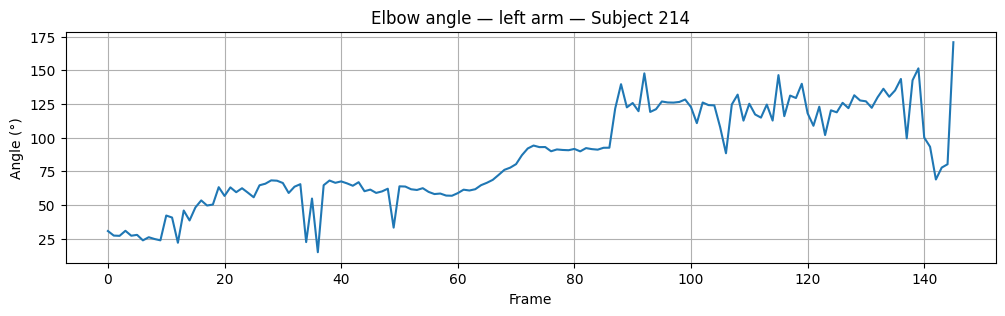

In [14]:
import matplotlib.pyplot as plt

sample = elbow_files[0]
df = pd.read_csv(sample['path'], header=None).values.astype(float)

a = angle3(df, 23, 7, 22)
print(f"Angle: min={a.min():.1f}°  max={a.max():.1f}°  range={a.max()-a.min():.1f}°")

plt.figure(figsize=(12,3))
plt.plot(a)
plt.title(f'Elbow angle — {sample["side"]} arm — Subject {sample["subject"]}')
plt.ylabel('Angle (°)'); plt.xlabel('Frame'); plt.grid(True)
plt.show()

In [15]:
import os
from collections import Counter

all_files = elbow_files  # already filtered to gesture 0 and 1

# show unique suffixes after the 5th underscore
suffixes = []
for f in all_files:
    name = os.path.basename(f['path'])
    parts = name.replace('.txt','').replace('.csv','').split('_')
    suffix = '_'.join(parts[5:]) if len(parts) > 5 else 'NO_SUFFIX'
    suffixes.append(suffix)

print("File name suffixes found:")
for s, count in Counter(suffixes).most_common():
    print(f"  {count:3d}  {s}")

File name suffixes found:
  540  stand
  306  chair
  154  wheelchair
   48  sit
   26  Stand-frame


In [23]:
# Inspect one group in detail
sample_group = list(groups.items())[0]
(subj, date, side, correct), group = sample_group

print(f"Subject={subj}, Date={date}, Side={side}, Correct={correct}")
print(f"Files in group: {len(group)}, GT reps={len(group)}")
print()

j_s, j_e, j_w = (JOINTS_RIGHT if side == 'right' else JOINTS_LEFT)

frames = []
for info in sorted(group, key=lambda x: int(x['rep_num'])):
    df = pd.read_csv(info['path'], header=None).values.astype(float)
    a = angle3(df, j_s, j_e, j_w)
    frames.append(a)
    print(f"  rep {info['rep_num']}: {len(a)} frames, "
          f"min={a.min():.1f}° max={a.max():.1f}° range={a.max()-a.min():.1f}°")

signal = np.concatenate(frames)
print(f"\nConcatenated: {len(signal)} frames total")
print(f"Signal: min={signal.min():.1f}° max={signal.max():.1f}° range={signal.max()-signal.min():.1f}°")

# check what FSM calibration does
fsm = ElbowFSM()
cal_ok = fsm.calibrate_from_signal(signal, fps=30.0)
print(f"FSM calibrated: {cal_ok}")
print(f"FLEX threshold: {fsm.flex_thresh:.1f}°, EXTEND threshold: {fsm.extend_thresh:.1f}°")

import matplotlib.pyplot as plt
plt.figure(figsize=(14,3))
plt.plot(signal)
# draw vertical lines where reps join
cumlen = 0
for a in frames[:-1]:
    cumlen += len(a)
    plt.axvline(cumlen, color='red', alpha=0.5, linestyle='--')
plt.title(f'Concatenated signal — Subject {subj} {side} arm (red = rep boundaries)')
plt.ylabel('Angle (°)'); plt.xlabel('Frame'); plt.grid(True)
plt.show()

Subject=201, Date=18, Side=right, Correct=2
Files in group: 20, GT reps=20

  rep 1: 29 frames, min=24.7° max=176.4° range=151.8°


ParserError: Error tokenizing data. C error: Expected 1 fields in line 2, saw 178
